# 05 — What makes a chamber easy or hard to find?

*Weeks 6–7*

Choose **two** studies. Each study changes one parameter while all other baseline parameters stay fixed. Use **expected significance** for clean, reproducible comparisons unless your mentor asks you to study statistical fluctuations explicitly.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## Helper: expected significance for a fixed exposure

The helper below is deliberately small. It returns the maximum expected significance in the map only for exploratory study plots; do not use that maximum from a noisy map to define the headline exposure time.


In [2]:
def expected_peak_significance(target, detector, days):
    mu_v, _, _ = sa.expected_counts(target, detector, days)
    mu_0, _, _ = sa.expected_counts(target.without_void(), detector, days)
    S = mg.expected_significance(mu_v, mu_0)
    return float(np.max(S))

target0 = mg.Pyramid(
    base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
    density=cfg.ROCK_DENSITY_G_CM3, void_centre=cfg.VOID_CENTRE_M,
    void_radius=cfg.VOID_RADIUS_M, has_void=True,
)
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)


## Study A — How small a chamber can we find?

Vary `void_radius` from 4 m to 20 m at fixed depth and 30 days. Before running, write down your prediction. Plot **expected** peak significance against radius and explain the trend. The chamber is defined by radius, so a “10 m chamber” means 10 m radius (20 m diameter).


In [3]:
# YOUR TURN


## Study B — Does depth matter?

Move the chamber centre to `z = 40 ... 110` m while keeping radius, detector and exposure fixed. Plot expected significance against depth and explain the competing geometry and energy-threshold effects.


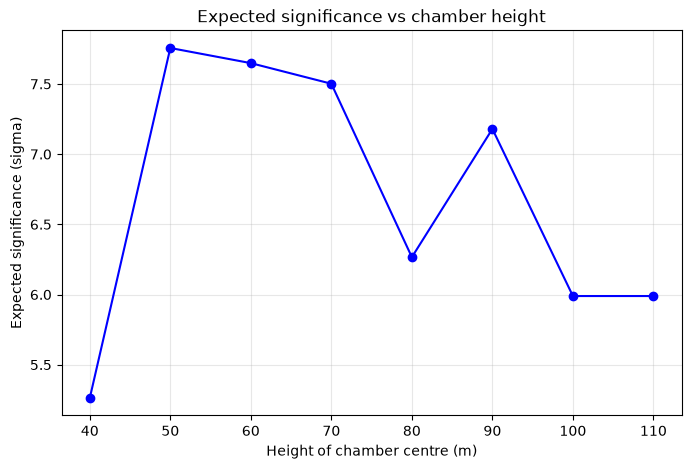

In [4]:
# YOUR TURN

days = 30.0
depths = np.arange (40, 111, 10)

peak_S = []

for d in depths:
    tgt = mg.Pyramid(
        base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
        density=cfg.ROCK_DENSITY_G_CM3, void_centre= (0, 0, float(d)),
        void_radius=cfg.VOID_RADIUS_M, has_void=True,
    )   
    peak_S.append(expected_peak_significance(tgt, detector, days))


plt.figure (figsize=(8,5));
plt.plot (depths, peak_S, marker= 'o', color = 'blue')

plt.xlabel('Height of chamber centre (m)')
plt.ylabel ('Expected significance (sigma)')
plt.title ('Expected significance vs chamber height')

plt.grid(alpha=0.3, which='both')
plt.show()

Explaination for the competing geometry and energy-threshold effects:

The expected significance peaks for chamber heights of around 50m and declines until 80m before increasing til 90m and decreasing again. 
This is because at 40m the void is slightly out of the +-40 degree field of view, which lowers the peak.
While the plateus at 80-90m and 100-110 are due to pixel sampling and discretised energy integral.
Therefore, only the overall trend of the graph should be interpreted.


## Study C — Where should the detector stand?

Keep the chamber fixed and move the detector position. Compare expected significance or expected exposure time, while making sure every detector position still has the chamber in its field of view. This is a simplified placement study, not a complete detector-engineering optimisation.


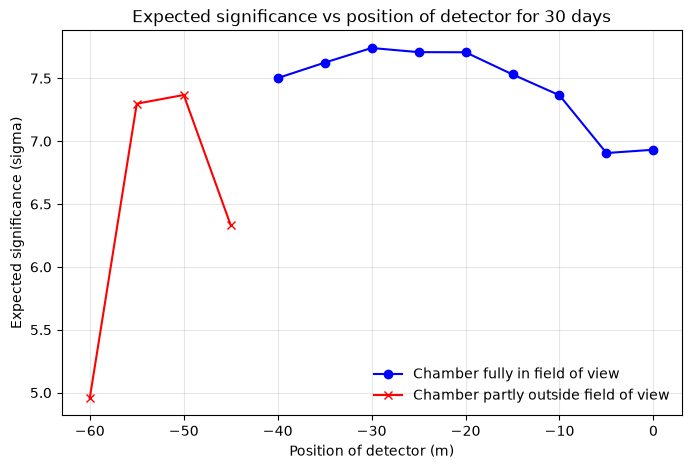

In [5]:
# YOUR TURN

days = 30.0
y_pos = np.arange(-60, 1, 5)

half_fov = cfg.FIELD_DEG/2.0
vc = np.array(cfg.VOID_CENTRE_M)

peak_S, in_view = [],[]

for y in y_pos: 
    det = np.array ([0.0, float(y), cfg.DETECTOR_POSITION_M[2]]) 
    dist = np.linalg.norm (vc - detector)
    centre_angle = np.degrees(np.arctan2(abs(vc[1]-y), vc[2] - det[2]))
    edge_angle = centre_angle + np.degrees(np.arcsin(cfg.VOID_RADIUS_M/dist))
    in_view.append(edge_angle <= half_fov)
    peak_S.append(expected_peak_significance(target0, det, days))

y_pos = np.asarray(y_pos)
peak_S = np.asarray(peak_S)
in_view = np.asarray(in_view)

plt.figure (figsize=(8,5));
plt.plot (y_pos[in_view], peak_S[in_view], marker= 'o', color = 'blue', label = 'Chamber fully in field of view')
plt.plot (y_pos[~in_view], peak_S[~in_view], marker= 'x', color = 'red', label = 'Chamber partly outside field of view')

plt.xlabel('Position of detector (m)')
plt.ylabel ('Expected significance (sigma)')
plt.title (f'Expected significance vs position of detector for {days:.0f} days')

plt.grid(alpha=0.3, which='both')
plt.legend (frameon = False)
plt.show()

## Study D — Angular bin size

Change `step_deg` from 1° to 5°. Coarser angular bins collect more events per bin but change the way the chamber signal is distributed among pixels. In this project this is a **binning study**, not a full simulation of detector angular resolution or a point-spread function.

State this limitation explicitly in your report.


In [6]:
# YOUR TURN


## Optional extension — a Malaysian target

Explore a Malaysian limestone hill or cave as a hypothetical target. Do not claim that no Malaysian muography survey exists unless you have independently verified that statement. The goal here is to build a plausible density model and estimate the exposure time that the same simulation pipeline would require.


In [7]:
# YOUR TURN


## Before demo day

Restart each notebook separately and use **Kernel → Restart & Run All**. The notebooks should not require you to run another notebook first. In particular, notebooks 03–05 should import the shared functions from `code/student_analysis.py`.
